# Agents, Session 7: The Three C's in Multi-Agent Systems

## Teams need more than talent

Think of a product team. Designers make mockups, developers write code, testers check quality. Three things make them a *team* rather than three people working alone:

- **Communication:** they share updates, ask questions and clarify requirements.
- **Coordination:** someone decides who does what and when, so work doesn't overlap or get stuck.
- **Cooperation:** they actively help each other, so the result is better than anyone could manage alone.

Agents need exactly the same three things. And they build on each other like the floors of a building:

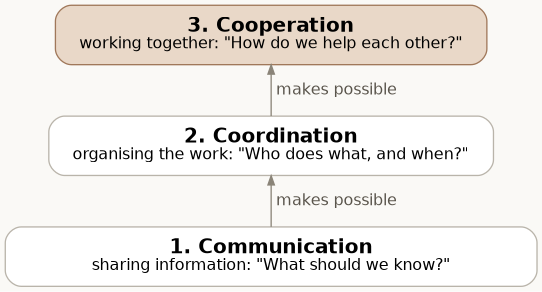

*Communication makes coordination possible; coordination makes cooperation possible.*

**If communication fails**, agents can't share basic information: chaos and duplicated work. **If coordination fails**, agents know what others are doing but nobody organises the work: missed steps and conflicts. **Only with both** can real cooperation happen.

Today we look at each C in theory, then build five small CrewAI teams that show them in action:

| Demo | What it shows | Main C |
|---|---|---|
| 1. Three ways to communicate | Shared memory, direct hand-off and broadcast, in one crew | Communication |
| 2. Manager / worker | A manager decides who does each task | Coordination (centralized) |
| 3. Sequential pipeline | Tasks in a fixed order, each feeding the next | Coordination (rule-based) |
| 4. Peer / swarm | Equals taking turns, and asking each other for help | Coordination (distributed) and cooperation |
| 5. Federated teams | A manager over specialist teams | All three together |

Every demo here also exists as a standalone Python script in the `scripts` folder, for running from a terminal.

### Setup

This notebook works in **Google Colab** and in **VS Code**. Your Gemini key can be in Colab Secrets (the key icon in the left sidebar, named `GOOGLE_API_KEY`) or in a `.env` file next to this notebook. If neither is set up, the setup cell asks you to paste it.

Installing CrewAI takes a minute or two. *In Colab: if a "Restart session" message appears afterwards, click it and carry on from the next cell.*

In [ ]:
%pip install -q "crewai[google-genai]>=1.15" requests python-dotenv

The setup cell does three things:

1. `CREWAI_TRACING_ENABLED = "false"` stops CrewAI from asking a yes/no question on its first run (in a notebook, that question would wait forever).
2. It finds your key: Colab Secrets first, then a `.env` file, otherwise it asks. (`google.colab` only exists on Colab, so in VS Code that step fails quietly and we move on.)
3. It creates the model every agent will use.

In [ ]:
import os
os.environ["CREWAI_TRACING_ENABLED"] = "false"

import requests
from getpass import getpass
from crewai import Agent, Task, Crew, Process, LLM
from crewai.tools import tool

try:
    from google.colab import userdata                        # only exists on Colab
    os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
except Exception:
    from dotenv import load_dotenv
    load_dotenv(".env")                                       # VS Code: read the .env file next to this notebook
if not os.getenv("GOOGLE_API_KEY"):
    os.environ["GOOGLE_API_KEY"] = getpass("Paste your Gemini API key: ")

llm = LLM(model="gemini/gemini-3.5-flash-lite", api_key=os.environ["GOOGLE_API_KEY"])
print("Ready:", llm.model)

Several agents today need to look things up, so here is one free tool they can share: a Wikipedia search. It needs no key. The `@tool("...")` line marks the function as a tool; the docstring is what agents read to decide when to use it.

In [ ]:
@tool("Wikipedia search")
def search_wikipedia(topic: str) -> str:
    """Search Wikipedia for a topic and return the opening of the best-matching article."""
    headers = {"User-Agent": "GenAI-course/1.0 (educational use)"}
    found = requests.get("https://en.wikipedia.org/w/api.php", headers=headers,
                         params={"action": "query", "list": "search", "srsearch": topic, "format": "json"}).json()
    results = found["query"]["search"]
    if len(results) == 0:
        return f"No Wikipedia article found for '{topic}'."
    title = results[0]["title"]
    page = requests.get("https://en.wikipedia.org/w/api.php", headers=headers,
                        params={"action": "query", "prop": "extracts", "exintro": 1, "explaintext": 1,
                                "titles": title, "format": "json"}).json()
    for page_id in page["query"]["pages"]:
        return f"{title}: " + page["query"]["pages"][page_id].get("extract", "")[:2500]
    return "No text found."

print(search_wikipedia.run("electric vehicles")[:150])

## 1. Communication: how agents share information

Communication is how agents **exchange information**: to share what they know, hand over work, and keep each other up to date. It can flow one-to-one, one-to-many, or through a shared space, and each of those gives a different **pattern**.

### Request–response (direct, one-to-one)

One agent sends a specific request to another and waits for the answer. Like emailing IT support: one sends, one replies.

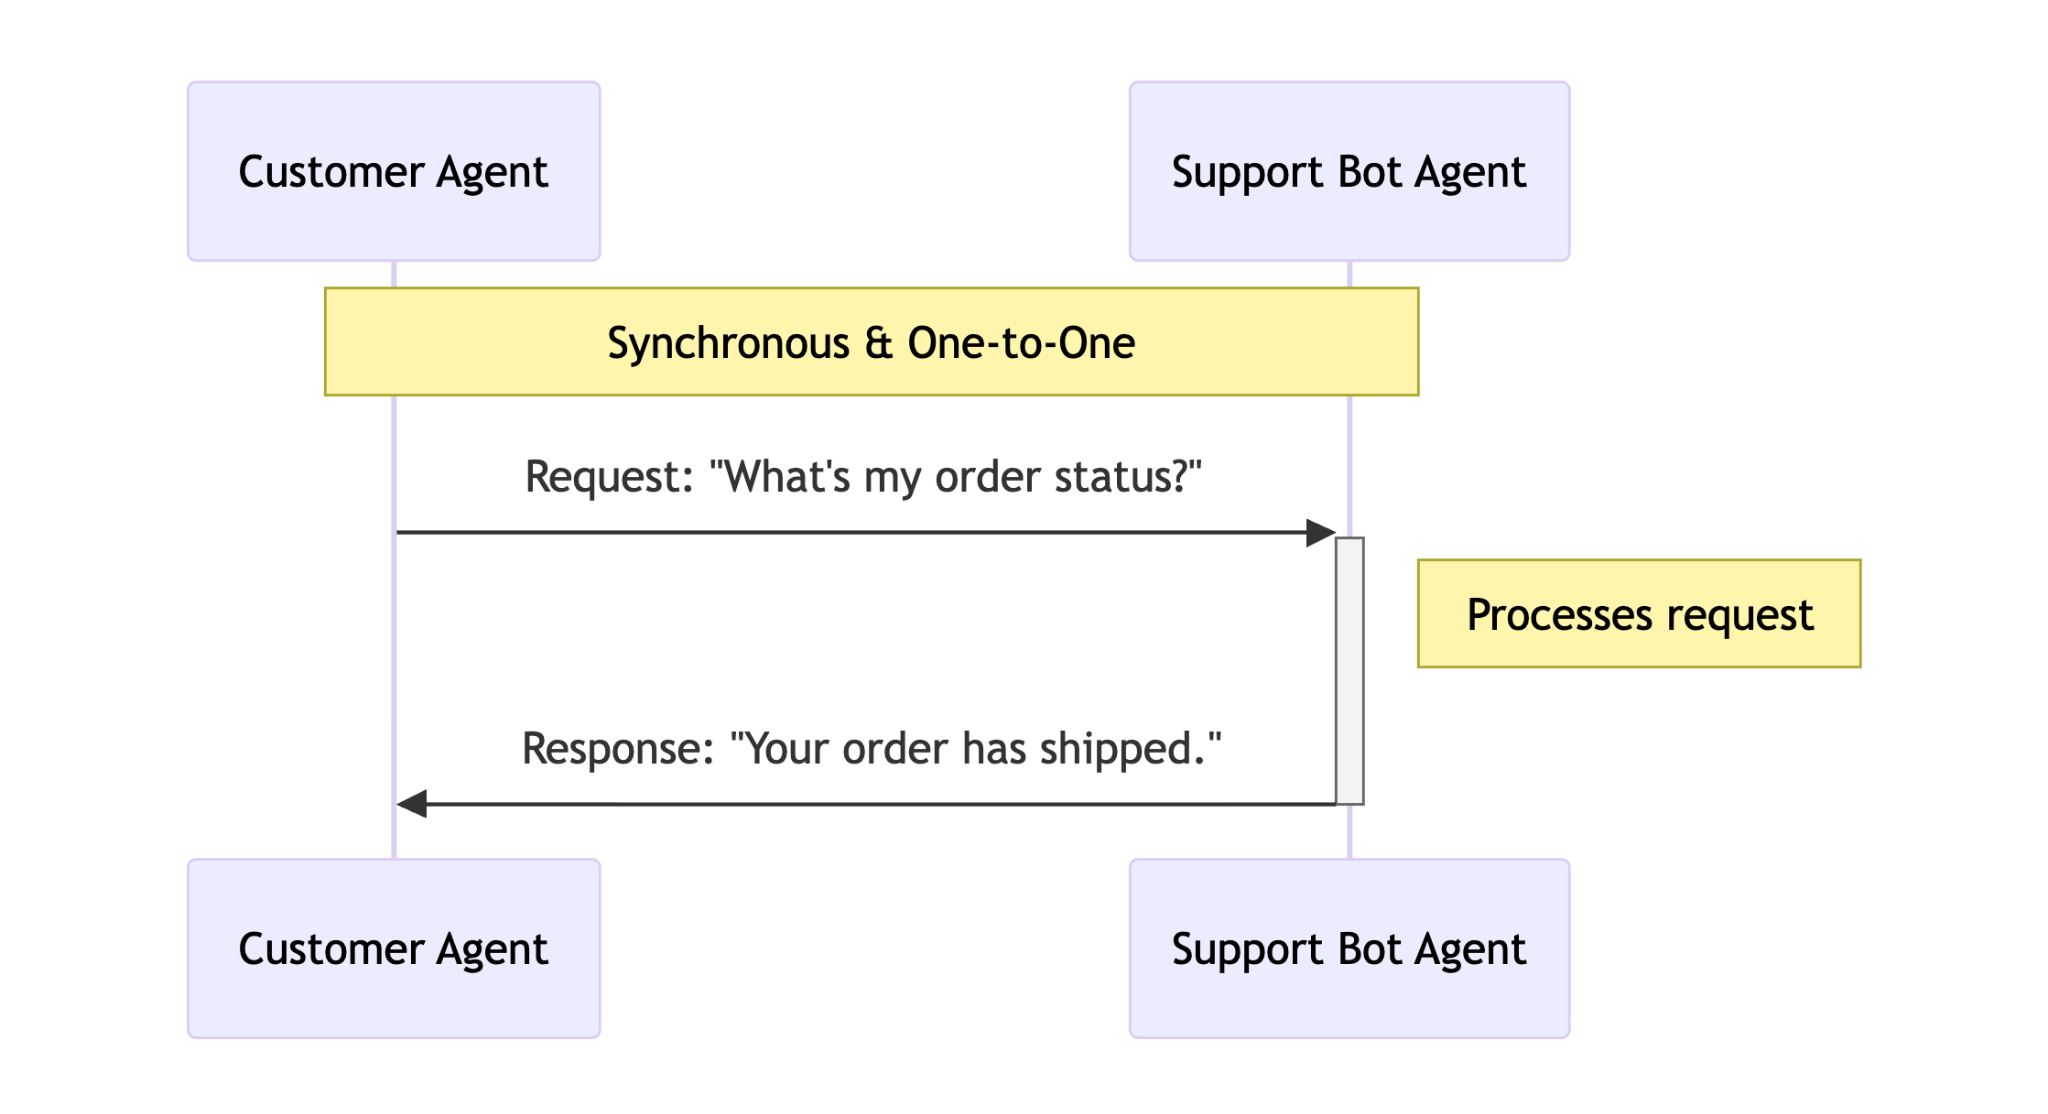

*Simple, reliable and easy to trace, but the sender has to wait, and it doesn't scale to big teams.*

### Publish–subscribe (broadcast, one-to-many)

One agent publishes a message to a topic, and every agent subscribed to that topic receives it. The publisher doesn't wait for replies. Like a company-wide announcement.

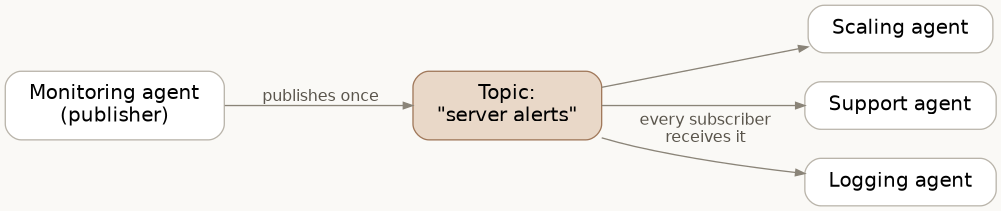

*Scalable and loosely connected, but there's no reply, and messages can pile up or arrive out of order.*

### Blackboard (shared memory, many-to-many)

Instead of messaging each other, agents read from and write to a **shared space**. Like a shared project board: the researcher posts facts, the writer reads them and posts a draft, the editor reviews it.

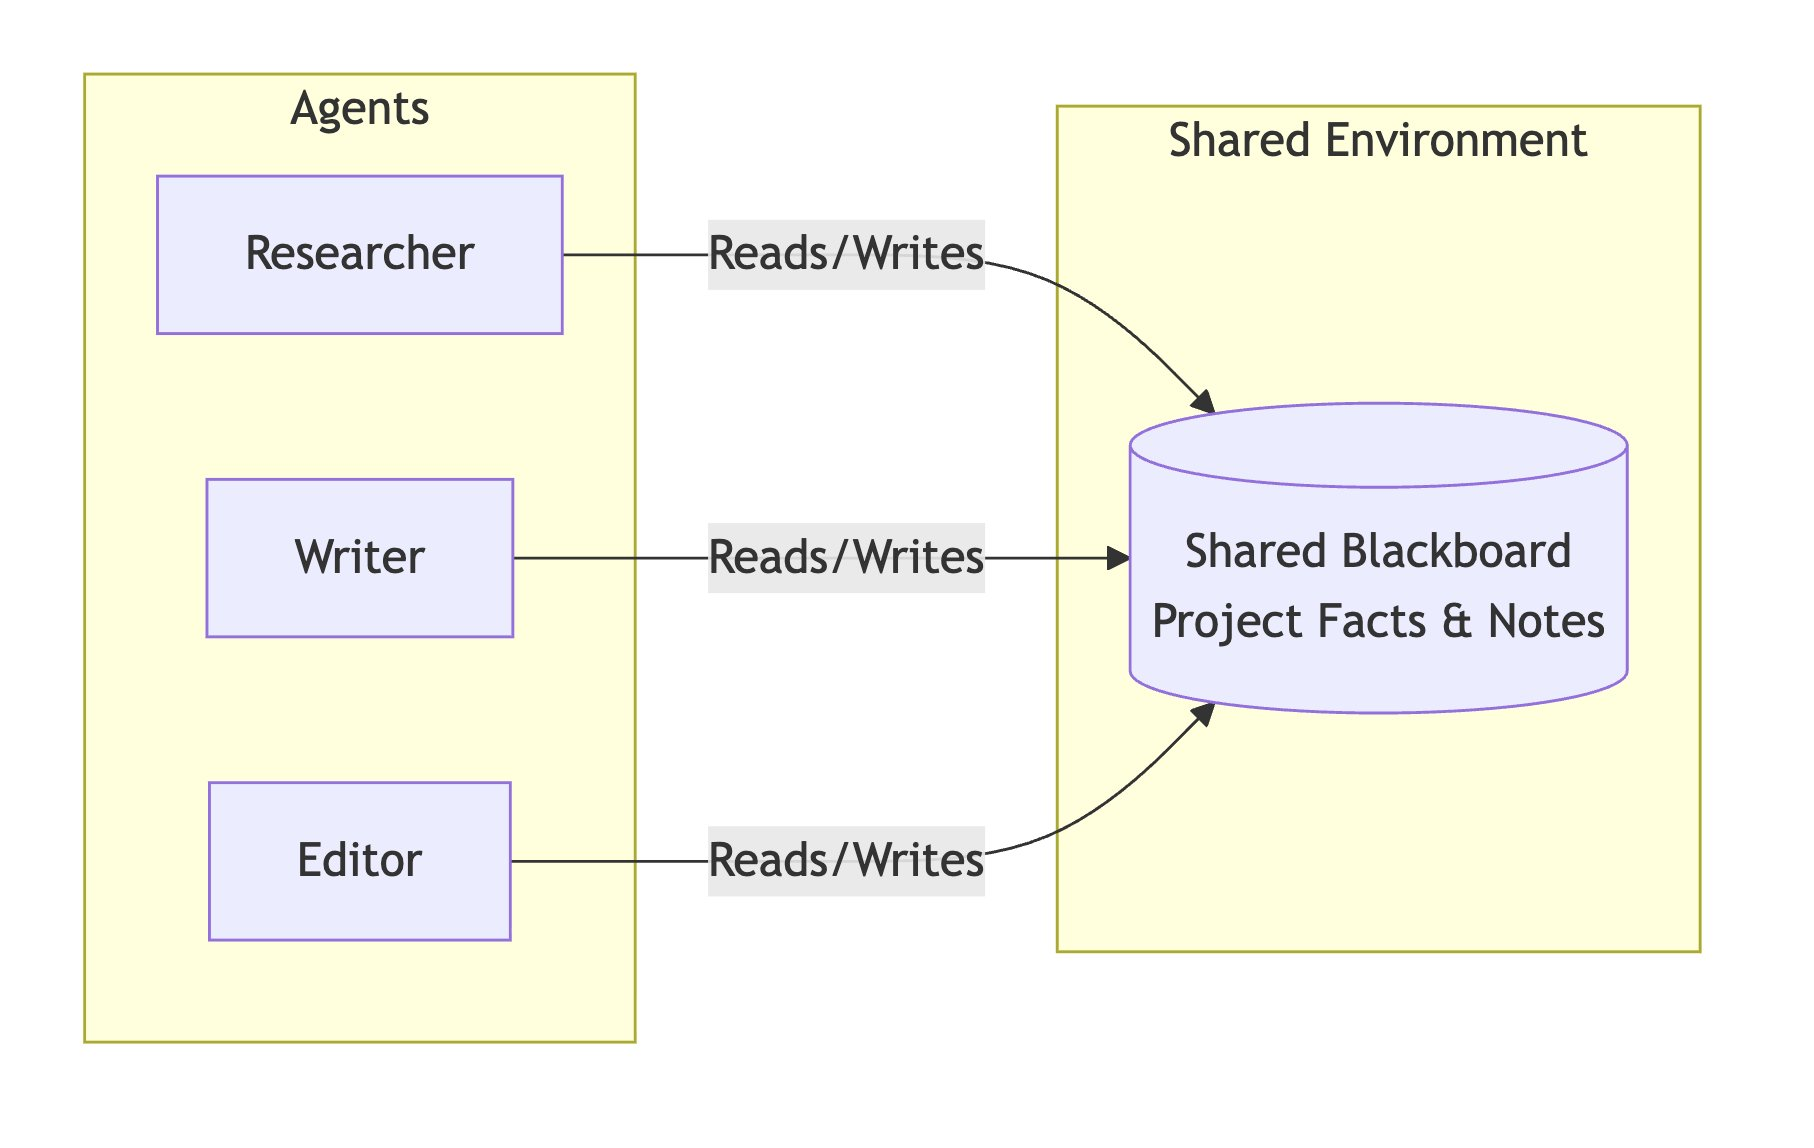

*Flexible and great for complex problems, but someone has to manage conflicts when two agents change the same thing.*

| Pattern | Flow | Style | Example | Strength | Weakness |
|---|---|---|---|---|---|
| Request–response | One-to-one | Waits for an answer | An email to support | Simple, reliable | Blocking, doesn't scale |
| Publish–subscribe | One-to-many | Doesn't wait | News alerts | Scalable | No feedback |
| Blackboard | Many-to-many | Doesn't wait | A shared project board | Flexible | Conflicts to manage |

### Demo 1: all three patterns in one crew

A researcher, a writer and an editor produce a short article. Each hand-off shows one pattern:

1. **Shared memory:** the researcher's findings are stored as a task result. The writer reads them through `context=[research_task]`, without asking the researcher anything.
2. **Direct:** the writer's draft goes one-to-one to the editor through `context=[writing_task]`.
3. **Broadcast:** the editor finishes with an announcement written for *everyone*, not for one agent.

In CrewAI all three use the same mechanism (task results and `context`). What changes is **who receives the information**: a shared store anyone can read, one specific agent, or everyone.

In [ ]:
researcher = Agent(role="Researcher", goal="Find accurate facts using Wikipedia.",
                   backstory="You only report what your sources say.", tools=[search_wikipedia], llm=llm)
writer = Agent(role="Writer", goal="Write a short, clear article from the research.",
               backstory="You write simply and only use the facts you're given.", llm=llm)
editor = Agent(role="Editor", goal="Polish the article and announce it to the whole team.",
               backstory="You fix mistakes, tighten the writing, and keep everyone informed.", llm=llm)
print("Three agents ready.")

In [ ]:
# 1. SHARED MEMORY: the research result is stored for later tasks to read
research_task = Task(description="Find 4 facts about {topic} using Wikipedia.",
                     expected_output="4 bullet points of facts.", agent=researcher)

# The writer reads the stored research, without messaging the researcher
writing_task = Task(description="Write a 120-word article about {topic} using the research.",
                    expected_output="A 120-word article.", agent=writer, context=[research_task])

# 2. DIRECT: the draft goes one-to-one to the editor.  3. BROADCAST: the editor announces to everyone
editing_task = Task(description=("Edit the article for clarity. Then add a final line that starts with "
                                 "'ANNOUNCEMENT TO ALL TEAMS:' saying the article is ready and what it's about."),
                    expected_output="The edited article, then the announcement line.", agent=editor, context=[writing_task])
print("Three tasks ready.")

In a notebook we run a crew with `await crew.kickoff_async(...)`. (Notebooks have a background "event loop"; `await` means "wait here for the answer". In a normal script, it's `crew.kickoff(...)`.) `max_rpm=4` keeps us within the free tier: at most 4 model calls a minute.

In [ ]:
comm_crew = Crew(agents=[researcher, writer, editor], tasks=[research_task, writing_task, editing_task],
                 process=Process.sequential, max_rpm=4)

result = await comm_crew.kickoff_async(inputs={"topic": "electric vehicles"})
for task_output in result.tasks_output:
    print(f"=== {task_output.agent} ===\n{task_output.raw}\n")

Read the three outputs in order: facts from the shared store, a draft passed directly to the editor, and an edited article ending with an announcement for everyone.

## 2. Coordination and cooperation

Communication shares information. **Coordination** organises that information into action: **who does what, and when**. **Cooperation** is agents actively working together towards a shared goal.

| | Coordination | Cooperation |
|---|---|---|
| Purpose | Manage dependencies and assign tasks | Achieve more together than alone |
| Question | Who does what, and when? | How do we help each other? |
| Example | A coordinator assigns tasks so no two agents do the same one | Agents improve each other's work to produce one better report |

### Three problems every team must solve

Picture a smart hospital with four agents: one extracts symptoms, one suggests a diagnosis, one suggests treatment, one writes the report for the doctor.

- **Task allocation: who does what?** The treatment agent mustn't start before the diagnosis exists. *Solutions:* a coordinator assigns tasks in order, or agents follow a fixed workflow.
- **Resource allocation: who uses a shared resource, and when?** The diagnosis and treatment agents both query the same medical knowledge API; if they hit it at once, it overloads. *Solutions:* a queue, priorities, or taking turns.
- **Conflict resolution: what if agents disagree?** One agent says "flu", another says "allergy". *Solutions:* a referee agent reviews both, the most confident answer wins, or several agents vote.

### Four ways to coordinate

| Mechanism | How it works | Like... | Strength | Weakness |
|---|---|---|---|---|
| **Centralized** | One agent decides who does what | A project manager | Simple, clear control | If the manager fails, everything stops |
| **Distributed** | Agents agree among themselves | Specialists dividing work without a boss | Robust, scalable | Slower: they have to negotiate |
| **Rule-based** | Agents follow fixed rules ("if research is done, start writing") | Standard operating procedures | Predictable, easy to debug | Can't handle surprises |
| **Learning-based** | Agents improve their teamwork from feedback over time | A team getting better every project | Adapts | Hard to build, unpredictable at first |

### Where you'll see these in the demos

- **Centralized coordination and task allocation:** Demos 2 and 5, where a manager decides.
- **Rule-based coordination:** Demo 3, where the order of tasks is a fixed rule.
- **Distributed coordination:** Demo 4, where peers sort out questions among themselves.
- **Resource allocation:** every crew today shares one resource, the Gemini API, which allows only a few calls a minute. `max_rpm=4` is resource allocation: it makes the agents take turns.
- **Conflict resolution:** the tester in Demo 4 and the editor in Demo 1 act as reviewers who catch problems before the work moves on.

## 3. The four design patterns in CrewAI

In Session 5 you met four design patterns: **manager/worker, peer/swarm, federated teams and sequential pipeline**. Here is how each one is built in CrewAI, and which of the Three C's it shows.

### Demo 2: manager / worker (centralized coordination)

A manager receives the tasks and decides which worker does each one. In CrewAI that's `Process.hierarchical` with `manager_llm=llm`: CrewAI creates the manager agent for you.

**The rule that makes it real:** don't assign the tasks to agents. If a task says `agent=...`, the manager can only pass it to that agent, so it has no choice to make.

First, the workers' tool. This is **pretend support data** for the exercise; a real company would read it from its support system.

In [ ]:
@tool("Customer support data")
def get_support_data(query: str) -> str:
    """Get last quarter's customer support summary: ticket counts, resolution times and feedback."""
    return ("Last quarter's support data:\n"
            "- 50 tickets: login issues (average 48 hours to resolve)\n"
            "- 30 tickets: billing errors (average 12 hours to resolve)\n"
            "- 20 tickets: feature requests (often closed without a fix)\n"
            "- Feedback: the password reset screen is confusing\n"
            "- Many calls about account verification")
print("Tool ready.")

In [ ]:
data_analyst = Agent(role="Customer support data analyst", goal="Find the biggest problems in the support data, with numbers.",
                     backstory="You read support data carefully and always quote the figures.", tools=[get_support_data], llm=llm)
process_optimizer = Agent(role="Process improvement specialist", goal="Turn the analysis into practical improvements.",
                          backstory="You suggest specific, realistic fixes, not vague advice.", llm=llm)
report_writer = Agent(role="Executive report writer", goal="Write a short, clear report for the company's COO.",
                      backstory="Your reports are brief, specific and easy to act on.", llm=llm)
print("Three workers ready.")

The tasks have **no `agent=`**. Notice `context=[...]` still works: communication between tasks doesn't depend on who does them.

In [ ]:
analysis_task = Task(description="Analyse last quarter's customer support data and find the main problems.",
                     expected_output="The main problems, with ticket counts and resolution times.")
improvement_task = Task(description="Based on the analysis, suggest three concrete improvements to the support process.",
                        expected_output="Three improvements, each one or two sentences.", context=[analysis_task])
coo_report_task = Task(description="Write a short report for the COO: a summary, the problems, and the improvements.",
                       expected_output="A report of about 200 words.", context=[analysis_task, improvement_task])

manager_crew = Crew(agents=[data_analyst, process_optimizer, report_writer],
                    tasks=[analysis_task, improvement_task, coo_report_task],
                    process=Process.hierarchical, manager_llm=llm, max_rpm=4, verbose=True)

result = await manager_crew.kickoff_async()
print("\n=== FINAL REPORT ===\n" + result.raw)

In the log, look for **`delegate_work_to_coworker`** (CrewAI may also write "Delegate work to coworker"): that's the manager choosing a worker for each task. That choice is **task allocation**, the first coordination problem, solved centrally.

### Demo 3: sequential pipeline (rule-based coordination)

Tasks run in a **fixed order**, each one's result feeding the next: research, then analysis, then a report. Like a CI/CD pipeline, where testing can't start until the code is built. In CrewAI that's `Process.sequential` with `context=[...]`.

The order itself is the rule: "when research is done, start the analysis". That's **rule-based coordination**: predictable and easy to debug.

In [ ]:
ai_researcher = Agent(role="AI research analyst", goal="Find well-documented facts about AI in software development, using Wikipedia.",
                      backstory="You never state a fact you haven't found in your research.", tools=[search_wikipedia], llm=llm)
analyst = Agent(role="Data analyst", goal="Pick the most promising idea from the research and explain why.",
                backstory="You turn raw research into a clear recommendation.", llm=llm)
summary_writer = Agent(role="Executive summary writer", goal="Write a short, polished summary for a business audience.",
                       backstory="You write clearly and only use facts you were given.", llm=llm)
print("Three pipeline stages ready.")

In [ ]:
ai_research_task = Task(description="Research three uses of AI in software development: large language models, automation and MLOps. Use Wikipedia.",
                        expected_output="A bullet list of three uses, two sentences each.", agent=ai_researcher)
choice_task = Task(description="From the research, choose the most promising use for a new software product, and explain why.",
                   expected_output="The chosen use, and three bullet-point reasons.", agent=analyst, context=[ai_research_task])
summary_task = Task(description="Write a one-page summary titled 'AI in Software Development': the chosen use, the reasons, a conclusion.",
                    expected_output="A summary of about 200 words.", agent=summary_writer, context=[choice_task])

pipeline_crew = Crew(agents=[ai_researcher, analyst, summary_writer], tasks=[ai_research_task, choice_task, summary_task],
                     process=Process.sequential, max_rpm=4)

result = await pipeline_crew.kickoff_async()
for task_output in result.tasks_output:
    print(f"=== {task_output.agent} ===\n{task_output.raw}\n")

Each stage did one job and handed its result to the next. Compare with Demo 2: there, a manager decided the order; here, **we** fixed it in advance.

*The original course file for this pattern used `verbose=2`, which CrewAI no longer accepts (`verbose` must be `True` or `False`), and its researcher had no tools, so its "latest trends" came from the model's memory. Ours reads Wikipedia.*

### Demo 4: peer / swarm (distributed coordination)

Three **equals** (a developer, a tester and a writer) work on one feature with **no manager**. They take turns, and each one can also **ask the others for help directly**, because of `allow_delegation=True`. That direct help is the peer-to-peer part.

CrewAI has no true "swarm" process, so, as in the session plan, the turns run in order with `Process.sequential`. The peers asking each other is what makes it more than a pipeline.

In [ ]:
developer = Agent(role="Software developer", goal="Write clean, correct, well-commented Python code.",
                  backstory="You write careful code and welcome questions from teammates.", llm=llm, allow_delegation=True)
tester = Agent(role="QA engineer", goal="Find bugs and edge cases before users do.",
               backstory="You think about what could go wrong. If something is unclear, you ask the developer.", llm=llm, allow_delegation=True)
doc_writer = Agent(role="Technical writer", goal="Write clear, accurate documentation for other developers.",
                   backstory="You explain code simply, and you check details with the developer when unsure.", llm=llm, allow_delegation=True)
print("Three peers ready.")

In [ ]:
coding_task = Task(description="Write a Python function called calculate_average that takes a list of numbers and returns their average. "
                               "Handle an empty list sensibly. Add comments.",
                   expected_output="The complete Python function.", agent=developer)
testing_task = Task(description="Review calculate_average. Think through test cases: positive numbers, negative numbers, and an empty list. "
                                "Report any bugs you find.",
                    expected_output="The test cases, the expected result of each, and any bugs found.", agent=tester, context=[coding_task])
docs_task = Task(description="Write documentation for calculate_average: what it does, its parameter, what it returns, "
                             "what happens with an empty list, and two usage examples.",
                 expected_output="Short documentation in Markdown.", agent=doc_writer, context=[coding_task, testing_task])

peer_crew = Crew(agents=[developer, tester, doc_writer], tasks=[coding_task, testing_task, docs_task],
                 process=Process.sequential, max_rpm=4, verbose=True)

result = await peer_crew.kickoff_async()
print("\n=== FINAL DOCUMENTATION ===\n" + result.raw)

In the log, look for **`ask_question_to_coworker`** (or "Ask question to coworker"): a peer asking another peer, with no manager involved. That's **distributed coordination**. And when the tester's report improves the documentation, that's **cooperation**: the result is better than any one of them would produce.

If no peer asked this time, that's a lesson too: `allow_delegation=True` makes asking *possible*, not *required*.

*The original course file for this pattern gave all three peers a "code review" tool that returned the same praise whatever code it received. We removed it: the tester now reviews the code itself, and can ask the developer.*

### Demo 5: federated teams (all three C's together)

A **project manager** oversees **specialist teams** and gives each part of the work to the right specialist:

- **Research team:** a researcher and a data analyst
- **Marketing team:** a content strategist

In CrewAI, that's `Process.hierarchical` with **our own manager**, `manager_agent=`. Two rules:

1. **Leave the task unassigned.** The original course file assigned it to the manager itself, so the manager's only "coworker" was itself, and the specialists were never used.
2. **A manager agent has no tools.** Its only job is to delegate.

In [ ]:
# Research team
lead_researcher = Agent(role="Lead researcher", goal="Find well-documented information about robotics trends, using Wikipedia.",
                        backstory="You research carefully and only report what your sources say.", tools=[search_wikipedia], llm=llm)
market_analyst = Agent(role="Market analyst", goal="Turn research into clear insights about market impact.",
                       backstory="You spot patterns and explain why they matter for businesses.", llm=llm)
# Marketing team
strategist = Agent(role="Content strategist", goal="Turn findings into an engaging summary for executives.",
                   backstory="You write clear executive summaries from the facts you're given.", llm=llm)
# The manager: no tools
project_manager = Agent(role="Project manager", goal="Deliver a high-quality report by giving each part of the work to the right specialist.",
                        backstory="You run research and marketing teams, and you know who is best for each job.", llm=llm)
print("Two teams and a manager ready.")

In [ ]:
robotics_task = Task(description="Create a report on three important robotics trends: (1) a short overview of each, "
                                 "(2) its likely market impact, (3) a summary for executives.",
                     expected_output="A well-structured report in Markdown, about 300 words.")   # no agent=

federated_crew = Crew(agents=[lead_researcher, market_analyst, strategist],   # the manager is NOT in this list
                      tasks=[robotics_task], process=Process.hierarchical, manager_agent=project_manager,
                      max_rpm=4, verbose=True)

result = await federated_crew.kickoff_async()
print("\n=== FINAL REPORT ===\n" + result.raw)

In the log, watch the project manager delegate to the researcher, the analyst and the strategist. All three C's at once: the manager **communicates** tasks and results, **coordinates** by choosing who does each part, and the teams **cooperate** to produce one report.

## 4. Recap: the Three C's in what you built

| Demo | Communication | Coordination | Cooperation |
|---|---|---|---|
| 1. Three patterns | Shared memory, direct hand-off, broadcast | Fixed order | Researcher, writer and editor build one article |
| 2. Manager / worker | Results passed through `context` | **Centralized:** a manager allocates tasks | Analysis, fixes and report combine |
| 3. Pipeline | Each stage hands its result to the next | **Rule-based:** the order is fixed | Each stage builds on the last |
| 4. Peer / swarm | Peers ask each other directly | **Distributed:** no boss | The tester's report improves the docs |
| 5. Federated teams | The manager sends tasks to teams | **Centralized,** over specialist teams | Research, analysis and writing combine |

And in every crew, `max_rpm=4` handled **resource allocation**: all the agents share one Gemini API and take turns using it.

### Conclusions

1. **The Three C's form a hierarchy.** Communication enables coordination, and coordination enables cooperation. Each layer depends on the one below it.
2. **Communication is the enabler, not the goal.** Sharing information only pays off when it supports organised, cooperative work.
3. **Coordination solves the practical problems:** task allocation, resource sharing and conflict resolution, centrally, by negotiation, or by rules.
4. **Cooperation creates synergy:** agents together achieve more than the sum of their individual work.
5. **Balance all three.** Excellence in one C alone isn't enough; good multi-agent systems integrate all three.

## Exercises

1. **[Easy]** In Demo 1, change the topic to "solar power" and run it again. Find the line where each communication pattern happens.
2. **[Easy]** In Demo 3, add a fourth stage: a fact checker that reviews the summary against the research. Which `context` does it need? Which coordination problem does it solve?
3. **[Medium]** In Demo 2, add `agent=report_writer` to the last task and run it again. What changed in the manager's behaviour? Was the manager worth its extra calls?
4. **[Medium]** In Demo 4, set `allow_delegation=False` on all three peers. Is it still a peer system, or just a pipeline? What did the team lose?
5. **[Hard]** Build a small hospital crew from Section 2: a symptom agent, a diagnosis agent and a treatment agent in a pipeline, plus a "referee" agent at the end that checks the diagnosis and treatment agree. Which coordination problem does the referee solve?

## Quick reference

| Idea | Code |
|---|---|
| Shared memory / direct hand-off | `Task(..., context=[earlier_task])` |
| Fixed order (rule-based) | `process=Process.sequential` |
| A manager decides (centralized) | `process=Process.hierarchical, manager_llm=llm`, tasks without `agent=` |
| Your own manager | `manager_agent=Agent(...)` with no tools, not in the `agents` list |
| Peers ask each other (distributed) | `allow_delegation=True` |
| Share an API fairly (resource allocation) | `max_rpm=4` |
| Watch the teamwork | `verbose=True` |
| Run in a notebook / in a script | `await crew.kickoff_async()` / `crew.kickoff()` |